In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
BASE = Path.cwd()
def find_file(name):
    for p in (BASE / name, Path('/mnt/data') / name):
        if p.exists(): return p
    raise FileNotFoundError(f'Не найден {name}: поместите файл рядом с notebook')
import sys
sys.path.insert(0, str(find_file('rink.py').parent))
from rink import plot_rink
pd.set_option('display.max_columns', 45)


## 1. Загрузка и проверка структуры
В исходном Excel есть служебный столбец `Unnamed: 0`, убираем его

In [5]:
events = pd.read_excel(find_file('NHL-playoffs-2026.xlsx'))
events = events.drop(columns=['Unnamed: 0'], errors='ignore')
events['Date'] = pd.to_datetime(events['Date'])
display(events.iloc[:10, [2,3,4,9,12]])
print('Shape:', events.shape, ', Игр:', events['Game ID'].nunique())

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Shape: (29710, 38) , Игр: 82


## 2. Таблица матчей
Берём последнюю запись каждого матча в порядке `Play ID`, чтобы получить окончательный счёт. `Period = 4` означает один овертайм, `Period = 5` — два. Корректируем колонку Outcome в соответствии с количествов овертаймов

In [8]:
last = (events.sort_values(['Game ID','Play ID']).groupby('Game ID', sort=True).tail(1).set_index('Game ID'))
games = last[['Date','Away Team','Home Team','Cumulated Away Score','Cumulated Home Score','Period']].copy()
games = games.rename(columns={'Cumulated Away Score':'Away Score','Cumulated Home Score':'Home Score'})
games['Outcome'] = games['Period'].map(lambda p: 'Final' if p<=3 else ('Final/OT' if p==4 else f'Final/{p-3}OT'))
games = games.drop(columns='Period').sort_index()
assert len(games)==82
assert games[['Away Score','Home Score']].notna().all().all()
print(games.columns)
display(games.iloc[-5:,-4:])

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')


,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


## 3. Функция `gameInfo(gameId)`

In [9]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({int(g['Home Score'])} - {int(g['Away Score'])}, "
            f"{g['Outcome']}, {g['Date']:%Y-%m-%d})")
print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Общее число голов и описательные статистики

In [10]:
games['Total Score'] = games['Away Score'] + games['Home Score']
display(games['Total Score'].describe().round(3))

,Total Score
count,82.000
mean,5.927
std,2.260
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,15.000


## 5. Распределение голов за матч
Краткий комментарий под графиком. Видно, что график соответствует описательной статистике из п. 4

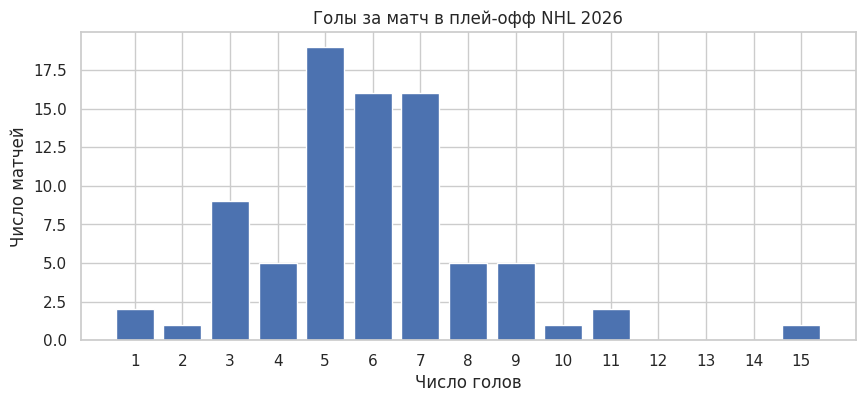

Чаще всего голов: 5 (матчей: 19); медиана: 6; среднее: 5.93.


In [11]:
fig, ax = plt.subplots(figsize=(10,4))
counts = games['Total Score'].value_counts().sort_index()
ax.bar(counts.index, counts.values)
ax.set_xticks(range(int(counts.index.min()), int(counts.index.max())+1))
ax.set(xlabel='Число голов', ylabel='Число матчей', title='Голы за матч в плей-офф NHL 2026')
plt.show()
print(f"Чаще всего голов: {counts.idxmax()} (матчей: {counts.max()}); медиана: {games['Total Score'].median():.0f}; среднее: {games['Total Score'].mean():.2f}.")

## 6. Самые и наименее результативные матчи

In [12]:
lo, hi = games['Total Score'].min(), games['Total Score'].max()
print('Минимум:', lo, '\n'+'\n'.join(map(gameInfo, games.index[games['Total Score']==lo])))
print('Максимум:', hi, '\n'+'\n'.join(map(gameInfo, games.index[games['Total Score']==hi])))

Минимум: 1 
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Максимум: 15 
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


## 7. Число уникальных участников матча
Учитываем игроков из шести слотов обеих команд **и** вратарей; повторные появления одного человека в матче считаются один раз.

Я вижу, что в примере у Game ID == 2025030216 указан 41 игрок, однако я **очень внимательно** проверила, и у меня получатся всё равно 40. На всякий случай в дополнительной ячейке ниже выведу уникальных игроков именно по этой игре, чтобы было видно, что 40 - правильный результат

In [14]:
away_cols = [f"Away Team's Player on the Ice #{i}" for i in range(1,7)] + ["Away Team's Goalie"]
home_cols = [f"Home Team's Player on the Ice #{i}" for i in range(1,7)] + ["Home Team's Goalie"]
def count_players(group, columns):
    return len(set(group[columns].stack().dropna().astype(str).str.strip()) - {''})
player_counts = events.groupby('Game ID').apply(lambda g: count_players(g, away_cols)+count_players(g, home_cols), include_groups=False)
most_players = pd.DataFrame({'Game Info':[gameInfo(i) for i in player_counts.index], 'Player Count':player_counts.values}, index=player_counts.index)
most_players.index.name='Game ID'
display(most_players.nlargest(10,'Player Count'))

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40
2025030112,"Buffalo Sabres - Boston Bruins (2 - 4, Final, ...",39
2025030114,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ...",39
2025030185,"Edmonton Oilers - Anaheim Ducks (4 - 1, Final,...",39
2025030215,"Buffalo Sabres - Montréal Canadiens (3 - 6, Fi...",39
2025030233,"Minnesota Wild - Colorado Avalanche (5 - 1, Fi...",39
2025030235,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi...",39
2025030243,"Anaheim Ducks - Vegas Golden Knights (2 - 6, F...",39
2025030413,Vegas Golden Knights - Carolina Hurricanes (5 ...,39


In [17]:
game_id = 2025030216
game = events[events["Game ID"] == game_id].copy()

away_cols = [
    c for c in game.columns
    if (
        c.startswith("Away Team")
        and ("Player on the Ice" in c or "Goalie" in c)
    )
]

home_cols = [
    c for c in game.columns
    if (
        c.startswith("Home Team")
        and ("Player on the Ice" in c or "Goalie" in c)
    )
]

def get_players(df, columns):
    players = (
        df[columns]
        .stack()
        .astype(str)
        .str.strip()
    )

    players = players[
        ~players.isin(["", "nan", "None"])
    ]

    return sorted(players.unique())

away_players = get_players(game, away_cols)
home_players = get_players(game, home_cols)

players_table = pd.DataFrame({
    "Гости": pd.Series(away_players),
    "Хозяева": pd.Series(home_players)
})

players_table.index += 1

display(players_table)

print(f"Гости: {len(away_players)}")
print(f"Хозяева: {len(home_players)}")
print(f"ВСЕГО: {len(away_players) + len(home_players)}")

,Гости,Хозяева
1,Alex Lyon,Alex Newhook
2,Alex Tuch,Alexandre Carrier
3,Beck Malenstyn,Alexandre Texier
4,Bowen Byram,Arber Xhekaj
5,Conor Timmins,Cole Caufield
6,Jack Quinn,Ivan Demidov
7,Jason Zucker,Jacob Fowler
8,Jordan Greenway,Jake Evans
9,Josh Doan,Jakub Dobes
10,Josh Norris,Joseph Veleno


Гости: 20
Хозяева: 20
ВСЕГО: 40

Столбцы гостей: ["Away Team's Player on the Ice #1", "Away Team's Player on the Ice #2", "Away Team's Player on the Ice #3", "Away Team's Player on the Ice #4", "Away Team's Player on the Ice #5", "Away Team's Player on the Ice #6", "Away Team's Goalie"]
Столбцы хозяев: ["Home Team's Player on the Ice #1", "Home Team's Player on the Ice #2", "Home Team's Player on the Ice #3", "Home Team's Player on the Ice #4", "Home Team's Player on the Ice #5", "Home Team's Player on the Ice #6", "Home Team's Goalie"]


## 8. Расстояние до ближайшей точки створа ворот


In [19]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot']

shots = events[events['Play Type'].isin(shot_types)].copy()

is_home = shots['Team Making the Play'] == shots['Home Team']
is_away = shots['Team Making the Play'] == shots['Away Team']

home_defends_left = shots["Home Team's Defending Side"] == 'left'
home_defends_right = shots["Home Team's Defending Side"] == 'right'

shots['Goal X'] = np.select(
    [
        is_home & home_defends_left,
        is_home & home_defends_right,
        is_away & home_defends_left,
        is_away & home_defends_right
    ],
    [89, -89, -89, 89],
    default=np.nan
)

x = pd.to_numeric(shots['X Coordinate on the Ice Rink'], errors='coerce')
y = pd.to_numeric(shots['Y Coordinate on the Ice Rink'], errors='coerce')

dx = np.abs(x - shots['Goal X'])
dy = np.maximum(np.abs(y) - 3, 0)

shots['Shot Length'] = np.sqrt(dx**2 + dy**2)

events['Shot Length'] = np.nan
events.loc[shots.index, 'Shot Length'] = shots['Shot Length']

display(
    events[
        events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])
    ][['Game ID', 'Play Type', 'Shot Length']]
)

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


## 9. Сравнение точных и неточных бросков
Чтобы убрать искажение от объема выборок, сначала нормируем данные.

Дальний хвост точных бросков может быть связан с бросками по пустым воротам

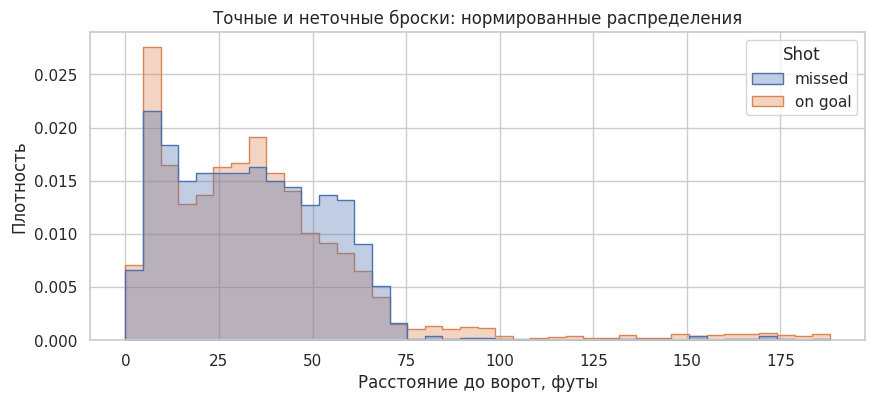

,count,mean,median
Shot,,,
missed,2643,34.01,32.25
on goal,4623,36.21,31.83


In [21]:
shots['Shot'] = np.where(shots['Play Type'].eq('missed-shot'),'missed','on goal')
fig,ax=plt.subplots(figsize=(10,4))
sns.histplot(data=shots.dropna(subset=['Shot Length']), x='Shot Length',hue='Shot',bins=40,stat='density',common_norm=False,element='step',alpha=.35,ax=ax)
ax.set(xlabel='Расстояние до ворот, футы',ylabel='Плотность',title='Точные и неточные броски: нормированные распределения')
plt.show()
display(shots.groupby('Shot')['Shot Length'].agg(['count','mean','median']).round(2))


## 10. Доля точных незаблокированных бросков в каждой игре

Вывод: точно бросков варьируется, но (визуально) не очень сильно (можно еще проанализировать дисперсию), в среднем оставаясь на уровне 0.639

Высокая точность удара в створ не всегда означает большое кол-во голов

In [23]:
shot_table = (shots.groupby(['Game ID','Team Making the Play','Play Type']).size().unstack(fill_value=0))
for c in shot_types:
    if c not in shot_table: shot_table[c]=0
shot_table['Accurate'] = shot_table['goal']+shot_table['shot-on-goal']
shot_table['All Unblocked'] = shot_table['Accurate']+shot_table['missed-shot']
shot_table['Share of Shots on Goal'] = shot_table['Accurate']/shot_table['All Unblocked']
numshots=shot_table
assert len(numshots)==164
assert numshots['Share of Shots on Goal'].between(0,1).all()
display(numshots['Share of Shots on Goal'].head(10))
print('Доля в среднем по командам-матчам:',round(numshots['Share of Shots on Goal'].mean(),3))

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
            Buffalo Sabres          0.681818
2025030114  Boston Bruins           0.600000
            Buffalo Sabres          0.648148
2025030115  Boston Bruins           0.630435
            Buffalo Sabres          0.490566
Name: Share of Shots on Goal, dtype: float64

Доля в среднем по командам-матчам: 0.639


## 11. Пять команд с самой высокой и самой низкой средней точностью

Здесь как раз видно разброс. Мне кажется, что разброс в среднем не очень высокий. хотя для лучшей и худшей команды он кажется существенным

In [24]:
avgnumshots = numshots.groupby(level='Team Making the Play')['Share of Shots on Goal'].mean()
print('Топ-5:');display(avgnumshots.nlargest(5).round(3))
print('Нижние 5:');display(avgnumshots.nsmallest(5).round(3))
print('Разброс между лучшей и худшей:',round(avgnumshots.max()-avgnumshots.min(),3))

Топ-5:


,Share of Shots on Goal
Team Making the Play,
Edmonton Oilers,0.706
Philadelphia Flyers,0.684
Dallas Stars,0.670
Minnesota Wild,0.656
Colorado Avalanche,0.653


Нижние 5:


,Share of Shots on Goal
Team Making the Play,
Pittsburgh Penguins,0.554
Utah Mammoth,0.599
Carolina Hurricanes,0.615
Tampa Bay Lightning,0.626
Buffalo Sabres,0.626


Разброс между лучшей и худшей: 0.152


## 12. Среднее число бросков в створ и голов за игру


In [25]:
team_games=pd.concat([games[['Away Team']].rename(columns={'Away Team':'Team'}),games[['Home Team']].rename(columns={'Home Team':'Team'})])['Team'].value_counts()
team_totals=shots.groupby('Team Making the Play')['Play Type'].value_counts().unstack(fill_value=0)
for c in shot_types:
    if c not in team_totals:team_totals[c]=0
avgshots=pd.DataFrame(index=team_games.index)
avgshots['Shot']=(team_totals['shot-on-goal']+team_totals['goal']).div(team_games)
avgshots['Goal']=team_totals['goal'].div(team_games)
avgshots=avgshots.sort_index()
assert len(avgshots)==16
display(avgshots.round(3))

,Shot,Goal
Team,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13. Регрессионная диаграмма: броски и голы

Вывод: положительная тенденция есть, но явной корелляции нет

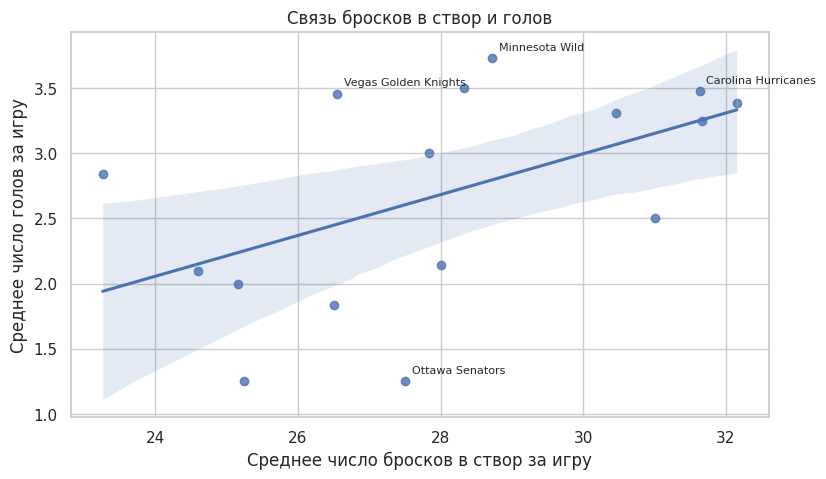

Корреляция Пирсона: r = 0.521. Положительная тенденция.


In [26]:
fig,ax=plt.subplots(figsize=(9,5))
sns.regplot(data=avgshots,x='Shot',y='Goal',ax=ax)
for team in ['Minnesota Wild','Vegas Golden Knights','Carolina Hurricanes','Ottawa Senators']:
    ax.annotate(team,(avgshots.loc[team,'Shot'],avgshots.loc[team,'Goal']),xytext=(5,6),textcoords='offset points',fontsize=8)
ax.set(xlabel='Среднее число бросков в створ за игру',ylabel='Среднее число голов за игру',title='Связь бросков в створ и голов')
plt.show()
r=avgshots['Shot'].corr(avgshots['Goal'])
print(f'Корреляция Пирсона: r = {r:.3f}.', 'Положительная тенденция.' if r>0 else 'Отрицательная тенденция.')

## 14. Матч с наибольшим числом всех бросков

In [28]:
all_shot_types=shot_types+['blocked-shot']
all_shots=events.loc[events['Play Type'].isin(all_shot_types)].copy()
shot_counts=all_shots.groupby('Game ID').size()
idxmax=shot_counts.idxmax()
print(gameInfo(idxmax),'\nБросков:',shot_counts.max())

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20) 
Бросков: 208


## 15. Все броски на хоккейной площадке

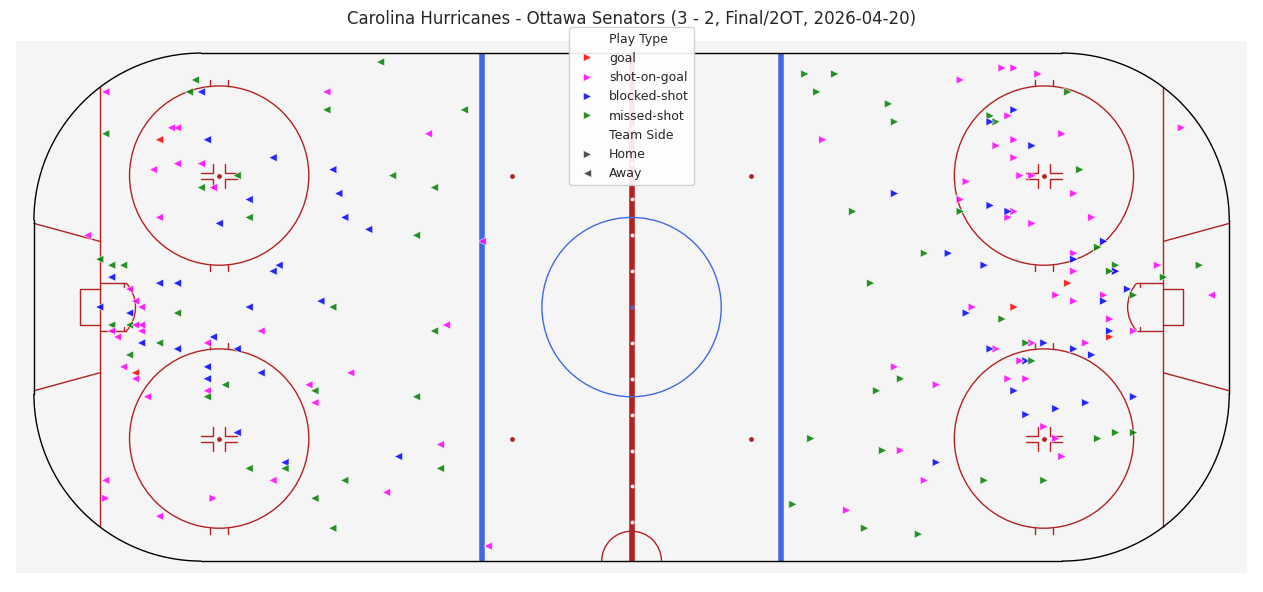

In [30]:
one = all_shots[all_shots['Game ID'] == idxmax].copy()

odd = one['Period'] % 2 == 1

one['Plot X'] = np.where(
    odd,
    -one['X Coordinate on the Ice Rink'],
    one['X Coordinate on the Ice Rink']
)

one['Plot Y'] = np.where(
    odd,
    -one['Y Coordinate on the Ice Rink'],
    one['Y Coordinate on the Ice Rink']
)

one['Team Side'] = np.where(
    one['Team Making the Play'] == one['Home Team'],
    'Home',
    'Away'
)

colors = {
    'goal': 'red',
    'shot-on-goal': 'magenta',
    'blocked-shot': 'blue',
    'missed-shot': 'green'
}

markers = {
    'Home': '>',
    'Away': '<'
}

fig, ax = plt.subplots(figsize=(13, 6))
plt.sca(ax)
plot_rink(False)

sns.scatterplot(
    data=one,
    x='Plot X',
    y='Plot Y',
    hue='Play Type',
    style='Team Side',
    hue_order=[
        'goal',
        'shot-on-goal',
        'blocked-shot',
        'missed-shot'
    ],
    style_order=['Home', 'Away'],
    palette=colors,
    markers=markers,
    s=35,
    alpha=0.85,
    ax=ax
)

ax.set_xlim(-104, 104)
ax.set_ylim(-46, 46)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(gameInfo(idxmax), fontsize=12)

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    fontsize=9,
    framealpha=0.9
)

plt.tight_layout()
plt.show()

## 16. Десять лучших снайперов

In [31]:
goals=events[events['Play Type'].eq('goal')].copy()
scorers=goals['Player in the Event #1'].value_counts().head(10)
display(scorers.rename('Голы').to_frame())

,Голы
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Nathan MacKinnon,7
Taylor Hall,7
Mark Stone,7


## 17. Десять лучших ассистентов

In [33]:
assists=pd.concat([goals['Player in the Event #2'],goals['Player in the Event #3']]).dropna().value_counts()
display(assists.head(10).rename('Передачи').to_frame())

,Передачи
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Taylor Hall,12
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Quinn Hughes,11
Kirill Kaprizov,11


## 18. Топ-10 по системе гол + пас

In [34]:
goal_counts=goals['Player in the Event #1'].value_counts()
points=goal_counts.add(assists,fill_value=0).sort_values(ascending=False).astype(int)
display(pd.DataFrame({'Голы':goal_counts,'Передачи':assists,'Очки':points}).fillna(0).astype(int).sort_values('Очки',ascending=False).head(10))

,Голы,Передачи,Очки
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Shea Theodore,6,12,18
Nikolaj Ehlers,8,10,18
Brett Howden,14,4,18
Nick Suzuki,4,12,16
Lane Hutson,3,13,16
Pavel Dorofeyev,12,4,16


## 19. Среднее число бросков в створ за игру у игроков


In [36]:
appearances=[]
for prefix, cols,teamcol in [('away',away_cols,'Away Team'),('home',home_cols,'Home Team')]:
    slots=events[['Game ID',teamcol]+cols].melt(id_vars=['Game ID',teamcol],value_vars=cols,value_name='Player').dropna(subset=['Player'])
    appearances.append(slots[['Game ID',teamcol,'Player']].rename(columns={teamcol:'Team'}))
appearances=pd.concat(appearances).drop_duplicates()

player_games=appearances.groupby(['Team','Player'])['Game ID'].nunique().rename('Games')
accurate=events[events['Play Type'].isin(['shot-on-goal','goal'])]
player_shots=accurate.groupby(['Team Making the Play','Player in the Event #1']).size()
player_shots.index=player_shots.index.set_names(['Team','Player'])
player_rates=pd.DataFrame({'Games':player_games,'Shots':player_shots}).fillna({'Shots':0})
player_rates['Shots per Game']=player_rates['Shots']/player_rates['Games']
display(player_rates.sort_values(['Shots per Game','Shots'],ascending=False).head(10).round(3))

,,Games,Shots,Shots per Game
Team,Player,,,
Dallas Stars,Jason Robertson,6,30.0,5.000
Utah Mammoth,Dylan Guenther,6,27.0,4.500
Tampa Bay Lightning,Nikita Kucherov,7,31.0,4.429
Minnesota Wild,Matt Boldy,11,48.0,4.364
Los Angeles Kings,Quinton Byfield,4,17.0,4.250
Tampa Bay Lightning,Darren Raddysh,7,28.0,4.000
Minnesota Wild,Joel Eriksson Ek,6,24.0,4.000
Los Angeles Kings,Alex Laferriere,4,15.0,3.750
Boston Bruins,David Pastrnak,6,22.0,3.667


## 20. Среднее число силовых приёмов за игру


In [37]:
hit_counts=events[events['Play Type'].eq('hit')].groupby(['Team Making the Play','Player in the Event #1']).size()
hit_counts.index=hit_counts.index.set_names(['Team','Player'])
hit_rates=pd.DataFrame({'Games':player_games,'Hits':hit_counts}).fillna({'Hits':0})
hit_rates['Hits per Game']=hit_rates['Hits']/hit_rates['Games']
display(hit_rates.sort_values(['Hits per Game','Hits'],ascending=False).head(10).round(3))

,,Games,Hits,Hits per Game
Team,Player,,,
Utah Mammoth,Lawson Crouse,6,38.0,6.333
Dallas Stars,Alexander Petrovic,1,6.0,6.000
Los Angeles Kings,Alex Turcotte,1,6.0,6.000
Minnesota Wild,Yakov Trenin,9,51.0,5.667
Ottawa Senators,Dylan Cozens,4,22.0,5.500
Edmonton Oilers,Vasily Podkolzin,6,32.0,5.333
Vegas Golden Knights,Ivan Barbashev,22,110.0,5.000
Minnesota Wild,Marcus Foligno,11,55.0,5.000
Philadelphia Flyers,Carl Grundstrom,3,15.0,5.000


## 21. Вратари, не пропустившие ни одного гола хотя бы в одном матче

Постаралась учесть все правила


In [39]:
goalie_games=[]
for side in ('Away','Home'):
    col=f"{side} Team's Goalie"
    tcol=f'{side} Team'
    records=events[['Game ID',tcol,col]].dropna(subset=[col]).drop_duplicates()
    records=records.rename(columns={tcol:'Team',col:'Goalie'})
    goalie_games.append(records)
goalie_games=pd.concat(goalie_games).drop_duplicates()
conceded=[]
for side,opponent in [('Away','Home'),('Home','Away')]:
    col=f"{side} Team's Goalie"
    goal_against=goals[goals['Team Making the Play'].eq(goals[f'{opponent} Team'])]
    t=goal_against[['Game ID',f'{side} Team',col]].dropna(subset=[col]).rename(columns={f'{side} Team':'Team',col:'Goalie'})
    conceded.append(t)
conceded=pd.concat(conceded).groupby(['Game ID','Team','Goalie']).size().rename('Goals Against')
keepers=goalie_games.set_index(['Game ID','Team','Goalie']).join(conceded).fillna({'Goals Against':0}).reset_index()
shutout_games=keepers[keepers['Goals Against'].eq(0)].sort_values(['Goalie','Game ID'])
print('Вратари с хотя бы одним матчем без пропущенных голов:',shutout_games['Goalie'].nunique())
display(shutout_games.groupby(['Team','Goalie']).agg(Матчей_без_пропущенных=('Game ID','nunique')).sort_values('Матчей_без_пропущенных',ascending=False))

Вратари с хотя бы одним матчем без пропущенных голов: 8


Матчей_без_пропущенных
Team                Goalie                                    
Carolina Hurricanes Frederik Andersen                        3
                    Brandon Bussi                            2
Philadelphia Flyers Dan Vladar                               2
Boston Bruins       Joonas Korpisalo                         1
Colorado Avalanche  Scott Wedgewood                          1
Montréal Canadiens  Jakub Dobes                              1
Pittsburgh Penguins Arturs Silovs                            1
Tampa Bay Lightning Andrei Vasilevskiy                       1

## 22. Вопрос

**Вопрос:** чаще ли побеждают хозяева площадки в плей-офф 2026 года? Существует ли статистически значимая тенденция к более частым победам гостевых команд в плей-офф NHL 2026?

Расчеты и ответы в ячейке ниже

Победы хозяев: 39/82 (47.6%)
Победы гостей: 43/82 (52.4%)
95% ДИ Уилсона: [41.8%; 62.9%]
Binomial test: p-value = 0.3703


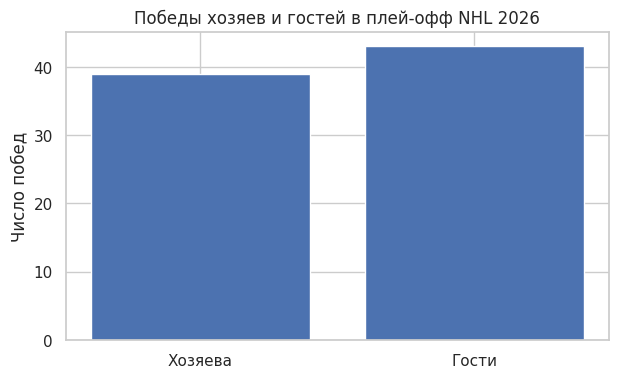

Статистически значимых свидетельств преимущества гостей нет.


In [41]:
from scipy.stats import binomtest
from math import sqrt

n_games = len(games)
home_wins = (games['Home Score'] > games['Away Score']).sum()
away_wins = n_games - home_wins

p = away_wins / n_games
alpha = 0.05

test = binomtest(
    k=away_wins,
    n=n_games,
    p=0.5,
    alternative='greater'
)

z = 1.96
den = 1 + z**2 / n_games
center = (p + z**2 / (2*n_games)) / den
half = z * sqrt(
    p*(1-p)/n_games + z**2/(4*n_games**2)
) / den

print(f'Победы хозяев: {home_wins}/{n_games} ({home_wins/n_games:.1%})')
print(f'Победы гостей: {away_wins}/{n_games} ({p:.1%})')
print(f'95% ДИ Уилсона: [{center-half:.1%}; {center+half:.1%}]')
print(f'Binomial test: p-value = {test.pvalue:.4f}')

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ['Хозяева', 'Гости'],
    [home_wins, away_wins]
)

ax.set(
    ylabel='Число побед',
    title='Победы хозяев и гостей в плей-офф NHL 2026'
)

plt.show()

if test.pvalue < alpha:
    print('Разница статистически значима: гости побеждают чаще.')
else:
    print('Статистически значимых свидетельств преимущества гостей нет.')